In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
diabetes = load_diabetes(as_frame=True)
df = diabetes.frame

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (442, 11)


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [3]:
X = df[["bmi"]]
y = df["target"]

print("Input feature: BMI")
print("Target: Disease progression score")
print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input feature: BMI
Target: Disease progression score
Input shape: (442, 1)
Target shape: (442,)


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 353
Testing samples: 89


In [5]:
model = LinearRegression()
model.fit(X_train, y_train)

print("Intercept:", model.intercept_)
print("BMI coefficient:", model.coef_[0])

Intercept: 152.00335421448167
BMI coefficient: 998.5776891375598


In [6]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE:", round(mae, 2))
print("RMSE:", round(rmse, 2))
print("R² Score:", round(r2, 3))

MAE: 52.26
RMSE: 63.73
R² Score: 0.233


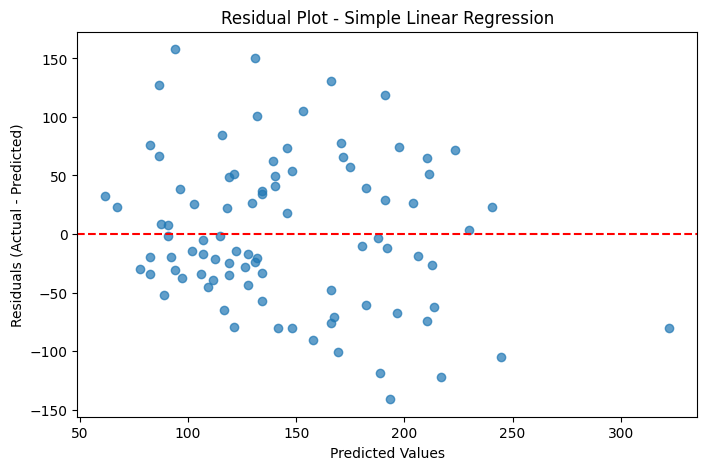

In [7]:
residuals = y_test - y_pred

plt.figure(figsize=(8, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Values")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Plot - Simple Linear Regression")
plt.show()

## Model Evaluation

- **MAE = 52.26:** The average absolute prediction error is approximately 52.26 target units.
- **RMSE = 63.73:** This metric penalizes larger prediction errors more heavily than MAE.
- **R² Score = 0.233:** The model explains approximately 23.3% of the variation in the test target.

### Interpretation
The model has limited predictive performance when using BMI as the only input feature. Other features may help improve predictions. The residual plot should also be examined for visible patterns and unusual errors.